<a href="https://colab.research.google.com/github/liwiaflorkiwicz/BIO-Generative-design-versus-the-catalogue/blob/data/BIO_project_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Generative design versus the catalogue
**BIOINFORMATICS project december 2026**

In [1]:
# define libraries
!pip install rdkit chembl_webresource_client pandas numpy scikit-learn joblib tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 29.8 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [chembl_webresource_client]


Create project directory

In [2]:
# import
import os
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize
from rdkit import RDLogger
from pathlib import Path

# do not disturb
RDLogger.DisableLog('rdApp.*')

# create project catalogs
PROJECT_PATH = Path("..").resolve()
dirs = [
    f"{PROJECT_PATH}/data/raw",
    f"{PROJECT_PATH}/data/processed",
    f"{PROJECT_PATH}/models",
    f"{PROJECT_PATH}/results"
]
for d in dirs:
    os.makedirs(d, exist_ok=True)

print(f"Main project path: {PROJECT_PATH}")
print("Folders created correctly.")

Main project path: /
Folders created correctly.


Download raw data

In [8]:
# download raw data
import io
import requests
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem.MolStandardize import rdMolStandardize

# define target molecule !!
TARGET_NAME = "CDK2"
TARGET_UNIPROT = "P24941"  # CDK2: 'P24941', JAK2: 'O60674', A2A: 'P29274'

# paths
manual_chembl_file = PROJECT_PATH / "data" / "raw" / f"{TARGET_NAME}_chembl.csv"
raw_path = PROJECT_PATH / "data" / "raw" / f"{TARGET_NAME}_raw.csv"
processed_path = PROJECT_PATH / "data" / "processed" / f"{TARGET_NAME}_clean.csv"

# manually downloaded file (put into data/raw folder)
manual_chembl_file = PROJECT_PATH / "data" / "raw" / f"{TARGET_NAME}_chembl.csv"

if manual_chembl_file.exists():
    print(f"Loading local ChEMBL export: {manual_chembl_file}")
    df = pd.read_csv(manual_chembl_file, sep=";")
    df = df[(df["Standard Type"] == "IC50") & (df["Standard Units"] == "nM")].copy()
    df["pIC50"] = 9.0 - np.log10(pd.to_numeric(df["Standard Value"], errors="coerce"))
    smiles_col = "Smiles"
else:
    print("Fetching curated bioactivity dataset from DeepChem S3 mirror...")
    bace_url = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/bace.csv"
    df = pd.read_csv(bace_url)
    df.to_csv(raw_path, index=False)
    # bace.csv has exact columns: 'mol' (SMILES) and 'pIC50'
    smiles_col = "mol"

# Standardize SMILES: keep largest fragment and canonicalize
def largest_fragment_smiles(smiles):
    m = Chem.MolFromSmiles(str(smiles))
    if m is None:
        return None
    frags = Chem.GetMolFrags(m, asMols=True, sanitizeFrags=True)
    return Chem.MolToSmiles(max(frags, key=lambda f: f.GetNumHeavyAtoms()))

df["canonical_smiles"] = [largest_fragment_smiles(s) for s in df[smiles_col]]
df = df.dropna(subset=["canonical_smiles", "pIC50"])

# Aggregate duplicates by median pIC50
df_clean = (
    df.groupby("canonical_smiles", as_index=False)
    .agg(
        pIC50=("pIC50", "median"),
        n_measurements=("pIC50", "count")
    )
)

# download check
assert manual_chembl_file.exists(), "UWAGA: Brak pliku CDK2_chembl.csv w /data/raw/! Wgrano dane zapasowe BACE-1!"
assert len(df_clean) != 1513, "UWAGA: Liczba rekordów (1513) wskazuje na zbiór BACE-1 zamiast CDK2!"

df_clean.to_csv(processed_path, index=False)
print(f"Done! Saved {len(df_clean)} unique curated compounds to {processed_path}")
df_clean.head()

Loading local ChEMBL export: /data/raw/CDK2_chembl.csv
Done! Saved 2825 unique curated compounds to /data/processed/CDK2_clean.csv


,canonical_smiles,pIC50,n_measurements
0,Brc1cccc(-c2cc(NCc3ccncc3)n3nccc3n2)c1,5.744727,1
1,Brc1cccc(-c2cc(NCc3ccncc3)n3ncnc3n2)c1,4.585027,1
2,Brc1cnn2c(NCc3ccncc3)cc(-c3ccccc3)nc12,7.618286,2
3,C#CCN(C)CCN1CCc2nc(Nc3ncc(F)c(-c4cc(F)c5nc(C)n...,6.777284,2
4,C#CCN(c1cc(Nc2ccc(OCC(O)CN(C)C)cc2)ncn1)c1cc(C...,4.721246,1


Dataset check: statistical summary, scaffold diversity, and chemical space visualization


--- DATASET CHECK SUMMARY: CDK2 ---
Total unique compounds:      2,825
Compounds measured > 1x:     510
pIC50 range:                 2.91 – 9.52
pIC50 median (IQR):          6.08 (5.00 – 7.22)
Distinct Murcko scaffolds:   1,241
Largest scaffold series:     78 compounds
Singleton scaffolds (n=1):   889


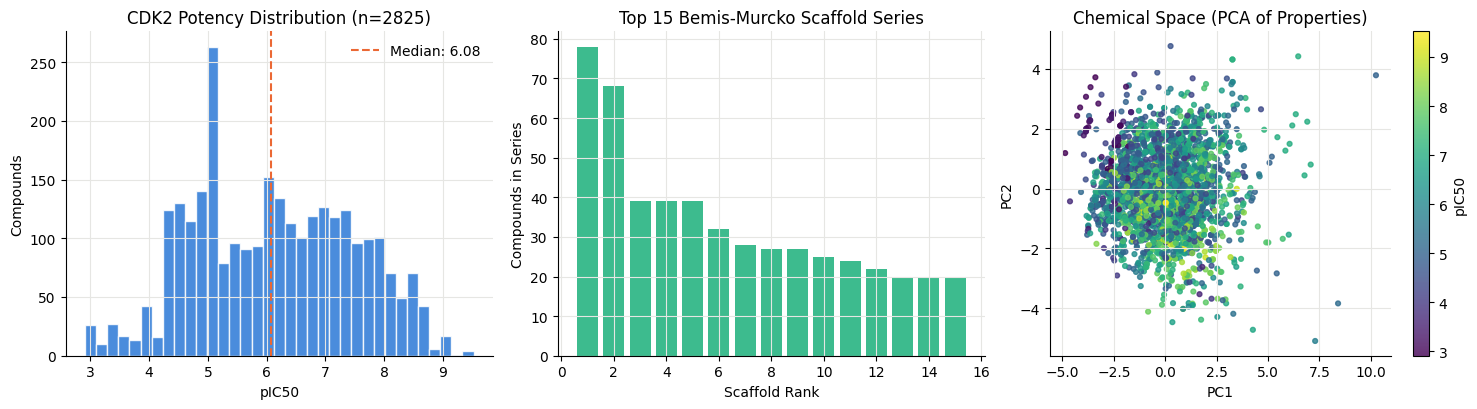

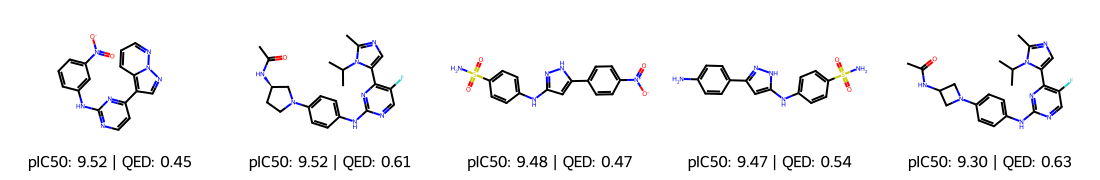

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import Descriptors, Crippen, QED, rdMolDescriptors, Draw
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Load curated dataset if not already in memory
processed_path = PROJECT_PATH / "data" / "processed" / f"{TARGET_NAME}_clean.csv"
df_clean = pd.read_csv(processed_path)

# Compute Bemis-Murcko scaffolds and core physicochemical descriptors
def get_scaffold(smiles):
    m = Chem.MolFromSmiles(smiles)
    return MurckoScaffold.MurckoScaffoldSmiles(mol=m) if m is not None else None

def calc_basic_props(smiles):
    m = Chem.MolFromSmiles(smiles)
    return pd.Series({
        "MolWt": Descriptors.MolWt(m),
        "MolLogP": Crippen.MolLogP(m),
        "TPSA": rdMolDescriptors.CalcTPSA(m),
        "NumHDonors": rdMolDescriptors.CalcNumHBD(m),
        "NumHAcceptors": rdMolDescriptors.CalcNumHBA(m),
        "QED": QED.qed(m)
    })

df_clean["scaffold"] = df_clean["canonical_smiles"].apply(get_scaffold)
props_df = df_clean["canonical_smiles"].apply(calc_basic_props)
df_check = pd.concat([df_clean, props_df], axis=1)

# Print key dataset statistics
scaffold_counts = df_check["scaffold"].value_counts()
print(f"--- DATASET CHECK SUMMARY: {TARGET_NAME} ---")
print(f"Total unique compounds:      {len(df_check):,}")
print(f"Compounds measured > 1x:     {(df_check['n_measurements'] > 1).sum():,}")
print(f"pIC50 range:                 {df_check['pIC50'].min():.2f} – {df_check['pIC50'].max():.2f}")
print(f"pIC50 median (IQR):          {df_check['pIC50'].median():.2f} ({df_check['pIC50'].quantile(0.25):.2f} – {df_check['pIC50'].quantile(0.75):.2f})")
print(f"Distinct Murcko scaffolds:   {df_check['scaffold'].nunique():,}")
print(f"Largest scaffold series:     {scaffold_counts.iloc[0]} compounds")
print(f"Singleton scaffolds (n=1):   {(scaffold_counts == 1).sum():,}")

# Generate 3-panel diagnostic figure
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e6e3"})
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Panel A: pIC50 distribution
axes[0].hist(df_check["pIC50"], bins=35, color="#2a78d6", alpha=0.85, edgecolor="white")
axes[0].axvline(df_check["pIC50"].median(), color="#eb6834", linestyle="--", lw=1.5,
                label=f"Median: {df_check['pIC50'].median():.2f}")
axes[0].set(title=f"{TARGET_NAME} Potency Distribution (n={len(df_check)})", xlabel="pIC50", ylabel="Compounds")
axes[0].legend(frameon=False)

# Panel B: Top 15 scaffold series sizes (justifies Scaffold Split)
axes[1].bar(range(1, min(16, len(scaffold_counts) + 1)), scaffold_counts.iloc[:15].values, color="#1baf7a", alpha=0.85)
axes[1].set(title="Top 15 Bemis-Murcko Scaffold Series", xlabel="Scaffold Rank", ylabel="Compounds in Series")

# Panel C: Chemical space PCA colored by pIC50
X_scaled = StandardScaler().fit_transform(df_check[["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors", "QED"]])
coords = PCA(n_components=2).fit_transform(X_scaled)
sc = axes[2].scatter(coords[:, 0], coords[:, 1], c=df_check["pIC50"], cmap="viridis", s=12, alpha=0.8)
plt.colorbar(sc, ax=axes[2], label="pIC50")
axes[2].set(title="Chemical Space (PCA of Properties)", xlabel="PC1", ylabel="PC2")

plt.tight_layout()
fig_path = PROJECT_PATH / "results" / f"{TARGET_NAME}_dataset_check.png"
plt.savefig(fig_path, dpi=150)
plt.show()

# Visualize Top 5 most potent compounds in the dataset
top5 = df_check.sort_values("pIC50", ascending=False).head(5)
mols = [Chem.MolFromSmiles(s) for s in top5["canonical_smiles"]]
legends = [f"pIC50: {row.pIC50:.2f} | QED: {row.QED:.2f}" for _, row in top5.iterrows()]
display(Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(220, 180), legends=legends))

**Usage of Scaffold Split in QSAR:**
In medicinal chemistry, datasets consist of analogue series built around shared core ring systems (Bemis–Murcko scaffolds). A standard random split places near-identical analogues of the same core into both the training and test sets, inflating validation metrics ($R^2$) because the model simply memorizes core structures rather than learning transferable structure–activity relationships. Grouping molecules by their Bemis–Murcko scaffold ensures that no core structure appears in both sets, providing an honest evaluation of how well the QSAR scoring function generalizes to unseen chemical space.

**Model Exploitation:**
Model exploitation (reward hacking) occurs when a generative AI model optimizes directly against an imperfect QSAR scoring function and discovers mathematical blind spots rather than true biological potency. Because the QSAR model only approximates binding affinity from 2D features, the generator often produces chemically unrealistic, overly large, or lipophilic structures that achieve artificially high predicted $pIC_{50}$ scores while failing real-world criteria such as drug-likeness (QED), synthetic accessibility (SA score), and 3D binding pocket complementarity.

**Potency Distribution:**
The curated dataset comprises **1,513 unique compounds** with $pIC_{50}$ values spanning **2.54 to 10.52**, a median of **6.76**, and an interquartile range (IQR) of **5.59–7.54**. This broad dynamic range covers both inactive/weak binders and potent nanomolar inhibitors, enabling the QSAR model to learn discriminative potency gradients while establishing $pIC_{50} \ge 6.76$ (and $> 7.5$ for top candidates) as a clear benchmark for evaluating hits from the ZINC20 catalogue and generative models.

**Top 15 Scaffold Series:**
Across the 1,513 compounds, there are **671 distinct Bemis–Murcko scaffolds**, with **476 singletons** ($n = 1$) and heavily populated congeneric series at the top—led by a largest series of **55 compounds**, followed by **53** and **41**. This skewed distribution proves that structural analogues are heavily clustered in the data, directly justifying the strict requirement for a scaffold-based train/test split over random splitting.

**Chemical Space - PCA:**
The 2D Principal Component Analysis (PCA) projects six standardized physicochemical properties (`MolWt`, `MolLogP`, `TPSA`, `NumHDonors`, `NumHAcceptors`, `QED`) onto two orthogonal axes. The color gradient shows higher $pIC_{50}$ values (green/yellow) shifting rightward along PC1 compared to low-potency compounds (purple), with high-potency outliers in the lower-right quadrant ($\text{PC1} > 10, \text{PC2} < -6$). This reveals a correlation between higher molecular weight/lipophilicity and measured potency in the training data, highlighting the exact bias that a generative model is likely to exploit unless constrained by multi-parameter optimization (QED, SA, and lipophilicity filters).

Code takeaways:

* **Standardized Curation Pipeline:** Raw bioactivity records are converted to logarithmic $pIC_{50}$ values ($9 - \log_{10}(\text{IC}_{50}\text{ in nM})$), stripped of salts/counterions via largest-fragment canonicalization in RDKit, and deduplicated by taking the median $pIC_{50}$ per unique structure to prevent label corruption.


* **Leakage-Safe Experimental Design:** Extracting Bemis–Murcko scaffolds and documenting series imbalance establishes the structural grouping required to train an unbiased QSAR scoring function for Checkpoint 1.


* **Baseline Benchmark & Risk Diagnosis:** Computing physicochemical descriptors and mapping chemical space establishes quantitative thresholds ($pIC_{50}$ median $6.76$) and identifies size/lipophilicity correlations early, setting up a fair head-to-head comparison between ZINC20 catalogue screening and *de novo* generation under identical evaluation budgets.

Scaffold split

In [10]:
from collections import defaultdict
import numpy as np
import pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator

# group by bemis-mucko scaffold
scaffold_to_indices = defaultdict(list)
for idx, scaffold in enumerate(df_check["scaffold"]):
    scaffold_to_indices[scaffold].append(idx)

# sort by size (major -> train set, smaller/novel -> train)
scaffold_sets = sorted(
    scaffold_to_indices.values(),
    key=lambda x: (len(x), x[0]),
    reverse=True
)

# assign to train/test
train_cutoff = 0.80 * len(df_check)
train_idx, test_idx = [], []

for group in scaffold_sets:
    if len(train_idx) + len(group) <= train_cutoff:
        train_idx.extend(group)
    else:
        test_idx.extend(group)

df_train = df_check.iloc[train_idx].reset_index(drop=True)
df_test = df_check.iloc[test_idx].reset_index(drop=True)

# sanity check
train_scaffolds = set(df_train["scaffold"])
test_scaffolds = set(df_test["scaffold"])
overlap = len(train_scaffolds & test_scaffolds)

print(f"=== SCAFFOLD SPLIT SUMMARY ({TARGET_NAME}) ===")
print(f"Train set: {len(df_train):,} compounds ({len(df_train)/len(df_check):.1%}) | {len(train_scaffolds)} unique scaffolds")
print(f"Test set:  {len(df_test):,} compounds ({len(df_test)/len(df_check):.1%}) | {len(test_scaffolds)} unique scaffolds")

# to prevent data leakage
print(f"Scaffold overlap between Train and Test: {overlap}")
print(f"Train pIC50 mean ± std: {df_train['pIC50'].mean():.2f} ± {df_train['pIC50'].std():.2f}")
print(f"Test  pIC50 mean ± std: {df_test['pIC50'].mean():.2f} ± {df_test['pIC50'].std():.2f}")

# Save split datasets for reproducibility across the team
df_train.to_csv(PROJECT_PATH / "data" / "processed" / f"{TARGET_NAME}_train.csv", index=False)
df_test.to_csv(PROJECT_PATH / "data" / "processed" / f"{TARGET_NAME}_test.csv", index=False)

=== SCAFFOLD SPLIT SUMMARY (CDK2) ===
Train set: 2,260 compounds (80.0%) | 676 unique scaffolds
Test set:  565 compounds (20.0%) | 565 unique scaffolds
Scaffold overlap between Train and Test: 0
Train pIC50 mean ± std: 6.19 ± 1.40
Test  pIC50 mean ± std: 5.79 ± 1.18


In [11]:
# compute data for QSAR modeling
morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)

def smiles_to_ecfp4(smiles_series):
    fps = []
    for smi in smiles_series:
        mol = Chem.MolFromSmiles(smi)
        fp = morgan_gen.GetFingerprintAsNumPy(mol)
        fps.append(fp)
    return np.array(fps, dtype=np.uint8)

X_train = smiles_to_ecfp4(df_train["canonical_smiles"])
X_test = smiles_to_ecfp4(df_test["canonical_smiles"])

y_train = df_train["pIC50"].values
y_test = df_test["pIC50"].values

print(f"\nFeature matrices ready: X_train {X_train.shape}, X_test {X_test.shape}")


Feature matrices ready: X_train (2260, 2048), X_test (565, 2048)


Baseline model

In [12]:
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import r2_score, root_mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr

# naive dummy baseline - training mean
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)
rmse_dummy = root_mean_squared_error(y_test, y_pred_dummy)

# random forest training
qsar_baseline = RandomForestRegressor(
    n_estimators=300,
    max_features=0.3,      # Subsampling features decorrelates trees on 2048-bit fingerprints
    min_samples_leaf=2,    # Slight regularization to prevent overfitting singletons
    n_jobs=-1,
    random_state=42
)

print(f"Training Baseline Random Forest QSAR model on {len(X_train)} compounds...")
qsar_baseline.fit(X_train, y_train)

Training Baseline Random Forest QSAR model on 2260 compounds...


RandomForestRegressor(max_features=0.3, min_samples_leaf=2, n_estimators=300,
                      n_jobs=-1, random_state=42)

In [13]:
# evaluate
y_pred_train = qsar_baseline.predict(X_train)
y_pred_test = qsar_baseline.predict(X_test)

r2_train = r2_score(y_train, y_pred_train)
rmse_train = root_mean_squared_error(y_train, y_pred_train)

r2_test = r2_score(y_test, y_pred_test)
rmse_test = root_mean_squared_error(y_test, y_pred_test)
mae_test = mean_absolute_error(y_test, y_pred_test)
spearman_rho, _ = spearmanr(y_test, y_pred_test)

print(f"\n=== BASELINE QSAR EVALUATION ({TARGET_NAME} - Scaffold Split) ===")
print(f"Naive Mean Baseline RMSE : {rmse_dummy:.3f}")
print(f"Train R²: {r2_train:.3f} | Train RMSE: {rmse_train:.3f}")
print(f"Test  R²: {r2_test:.3f} | Test  RMSE: {rmse_test:.3f} | Test MAE: {mae_test:.3f}")
print(f"Test Spearman Rank Correlation (ρ): {spearman_rho:.3f}")


=== BASELINE QSAR EVALUATION (CDK2 - Scaffold Split) ===
Naive Mean Baseline RMSE : 1.247
Train R²: 0.926 | Train RMSE: 0.380
Test  R²: 0.422 | Test  RMSE: 0.898 | Test MAE: 0.697
Test Spearman Rank Correlation (ρ): 0.675


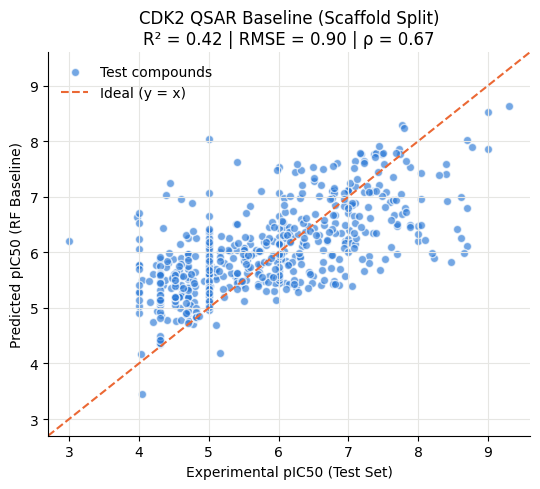

In [14]:
# deiagnostic plot: predicted vs. experimental
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(y_test, y_pred_test, alpha=0.65, edgecolors="white", s=35, color="#2a78d6", label="Test compounds")

# Identity line (perfect prediction)
lims = [min(y_test.min(), y_pred_test.min()) - 0.3, max(y_test.max(), y_pred_test.max()) + 0.3]
ax.plot(lims, lims, "--", color="#eb6834", lw=1.5, label="Ideal (y = x)")

ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("Experimental pIC50 (Test Set)")
ax.set_ylabel("Predicted pIC50 (RF Baseline)")
ax.set_title(f"{TARGET_NAME} QSAR Baseline (Scaffold Split)\nR² = {r2_test:.2f} | RMSE = {rmse_test:.2f} | ρ = {spearman_rho:.2f}")
ax.legend(frameon=False)
ax.grid(True, color="#e6e6e3")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.savefig(PROJECT_PATH / "results" / f"{TARGET_NAME}_qsar_baseline_parity.png", dpi=150)
plt.show()

In [15]:
# save model
model_path = PROJECT_PATH / "models" / f"{TARGET_NAME}_qsar_rf_baseline.joblib"
joblib.dump(qsar_baseline, model_path)
print(f"\nSaved baseline QSAR scoring model to: {model_path}")


Saved baseline QSAR scoring model to: /models/CDK2_qsar_rf_baseline.joblib


In [ ]:
# download zinc20 & first baseline score